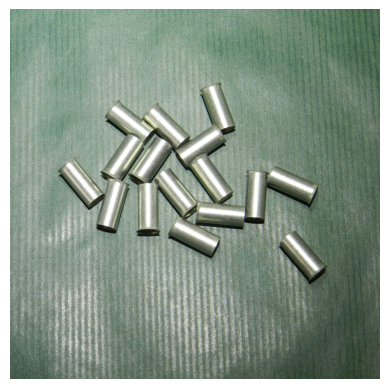

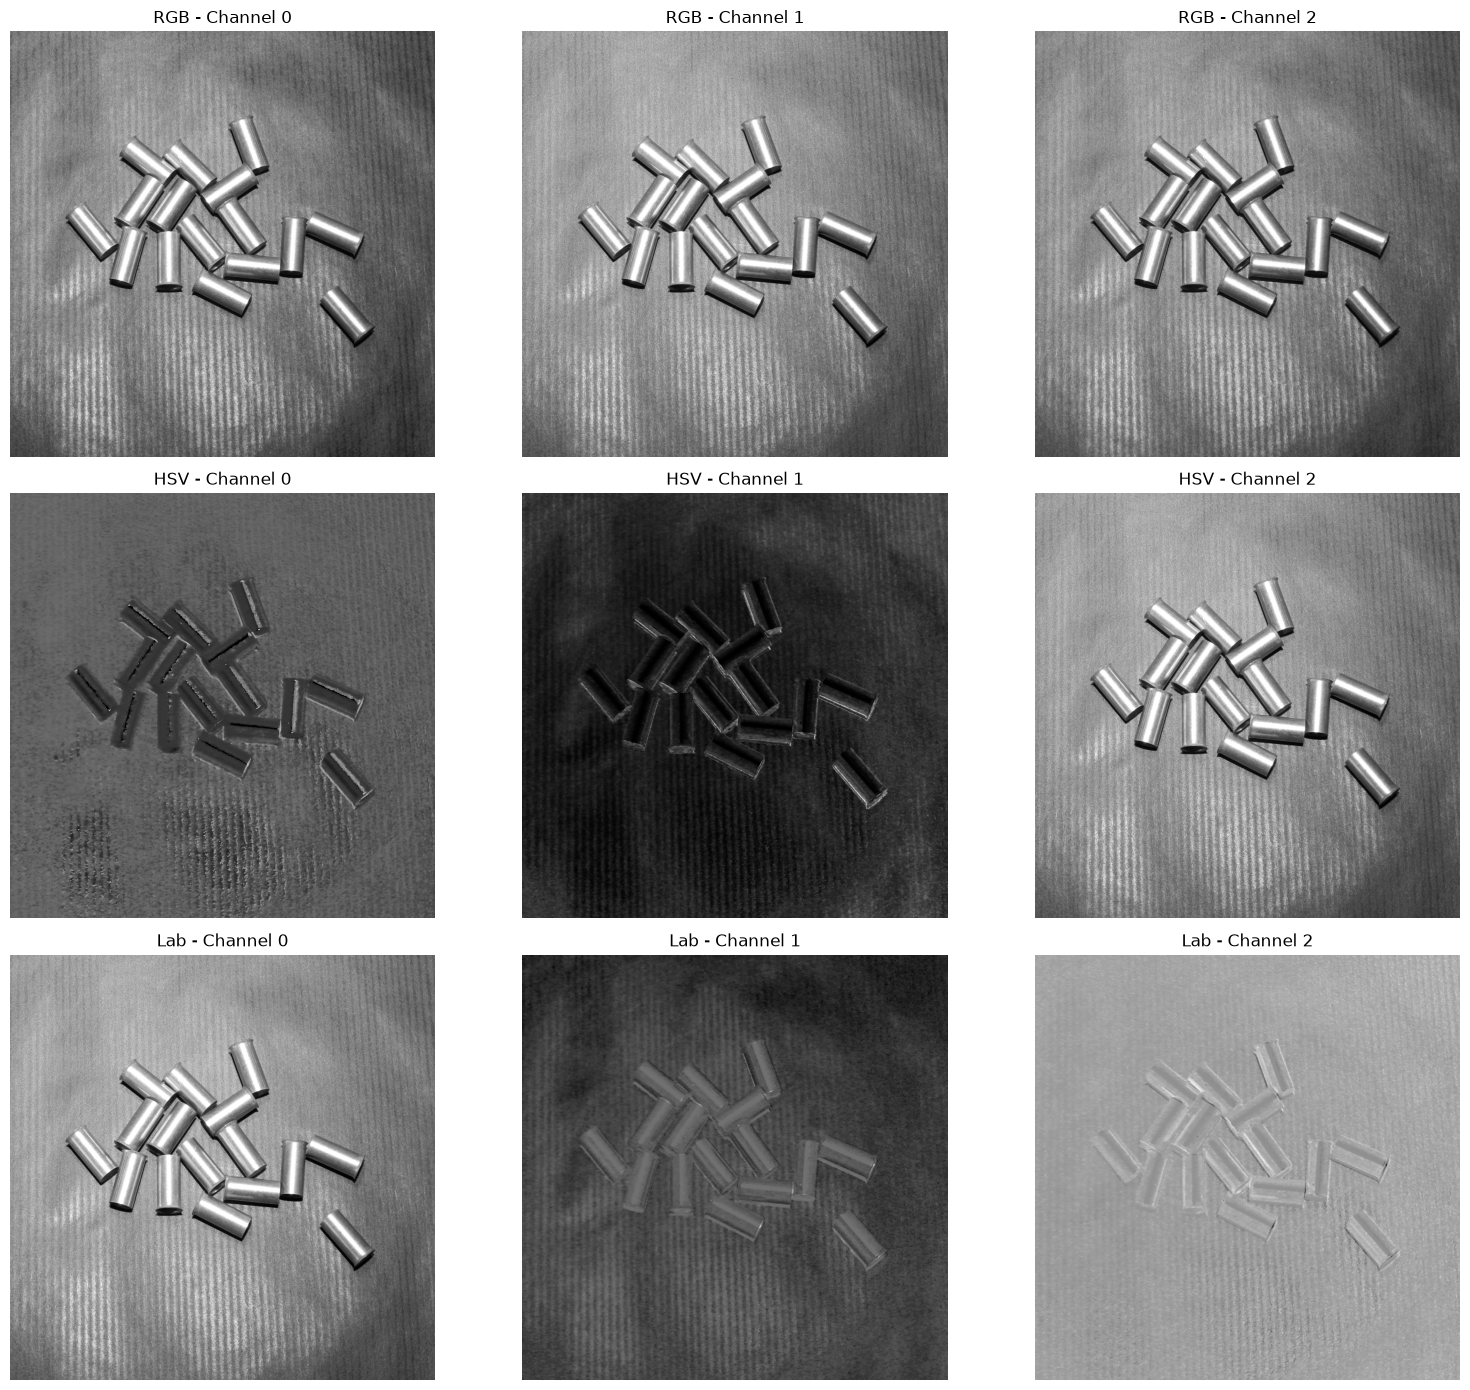

In [440]:
import cv2 as cv
import matplotlib.pyplot as plt

img = cv.imread("TubesDataset/0029.png") # load test image

def converted_images(image, color_converts): # convert to different colorspaces
    images = []
    for colorspace, converters in color_converts:
        converted_image = cv.cvtColor(image, converters)
        images.append((colorspace, converted_image))

    return images

def channel_colorspaces(images): # display different colorspaces and channels
    fig, axes = plt.subplots(3, 3, figsize=(16, 14))

    for i, (colorspace, converted_image) in enumerate(images):
        channels = cv.split(converted_image)

        for j, channel in enumerate(channels):
            axes[i, j].imshow(channel, cmap="gray")
            axes[i, j].set_title(f"{colorspace} - Channel {j}")
            axes[i, j].axis("off")

    plt.tight_layout()
    plt.show()

colorsplaces = [
    ("RGB", cv.COLOR_BGR2RGB), 
    ("HSV", cv.COLOR_BGR2HSV), 
    ("Lab", cv.COLOR_BGR2Lab)
]

images = converted_images(img, colorsplaces)

img_org = cv.cvtColor(img, cv.COLOR_BGR2RGB) # original image

plt.imshow(img_org)
plt.axis("off")
plt.show()

channel_colorspaces(images)

    


Looking for distinct edges, difference between background and tubes, and less reflection from teh original image.
RGB channel 1 looks interesting, and especially HSV and Lab -colorspace. Further, I will add blur to remove som noise and reflection from the background. 

In [441]:
import numpy as np

def display_images(images, zoom=0, org_im=False):

    n_im = len(images)
    fig, axes = plt.subplots(1, n_im, figsize=(16, 14), squeeze=False)
    axes = axes.flatten()
    for j, (description, image) in enumerate(images):

        if zoom:
            h, w = image.shape[:2]

            crop_h = int(h / zoom) # find the middle
            crop_w = int(w / zoom)

            y = (h - crop_h) // 2 # coordiantes
            x = (w - crop_w) // 2

            image = image[y:y+crop_h, x:x+crop_w] # zoom

        axes[j].imshow(image, cmap="gray")
        axes[j].set_title(description)
        axes[j].axis("off")
    plt.tight_layout()
    plt.show()


# promesing colorspaces from last check
colorspaces = [
    ("HSV", cv.COLOR_BGR2HSV), 
    ("Lab", cv.COLOR_BGR2Lab)
]

img_colorspace = converted_images(img, colorspaces) # converting the image to HSV and Lab
hsv_r, hsv_g, hsv_b = cv.split(img_colorspace[0][1]) # hsv g- space
lab_r, lab_g, lab_b = cv.split(img_colorspace[1][1]) # lab g- space


# testing different blurs
def gaussian_blur(img, ksize, sigma=0):
    out = []
    for kernel in ksize:
        blur = cv.GaussianBlur(img, kernel, sigma)
        out.append((f"Gauss blur: ksize: {kernel}", blur))

    return out

def median_blur(img, ksize):
    out = []
    for kernel in ksize:
        blur = cv.medianBlur(img, kernel)
        out.append((f"Median blur: ksize: {kernel}", blur))

    return out


As we can see, it is not much differance between the different blurs yet, but this can change

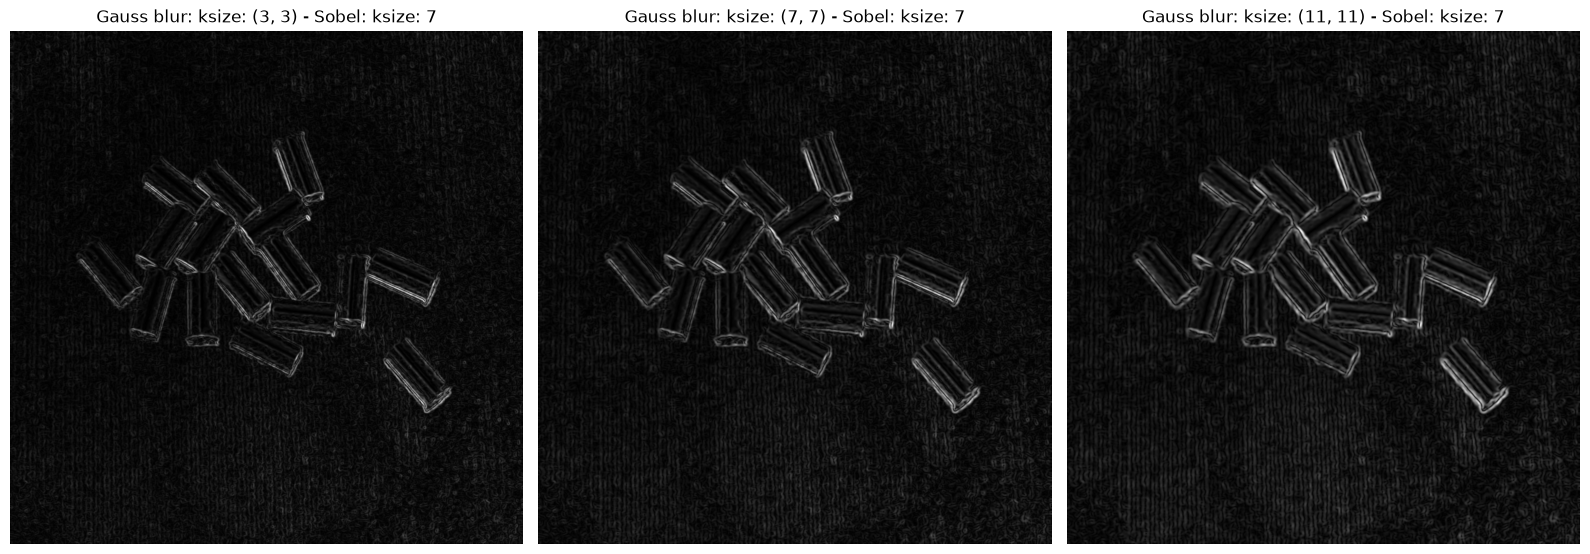

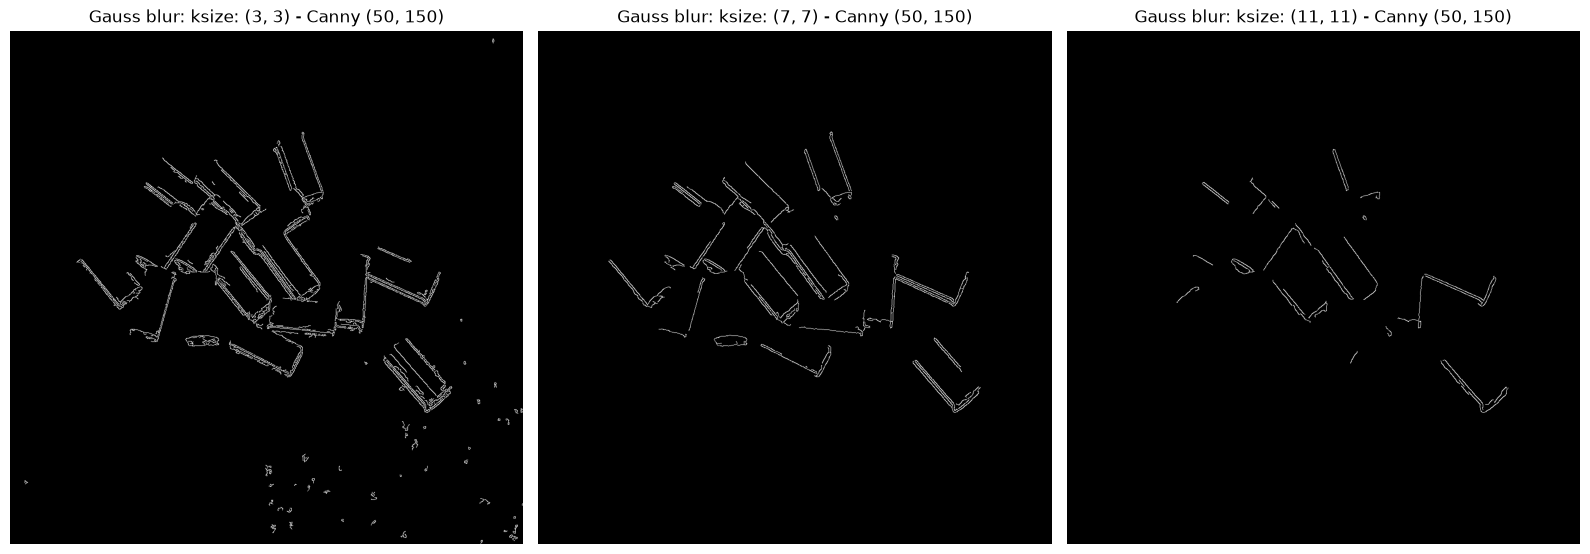

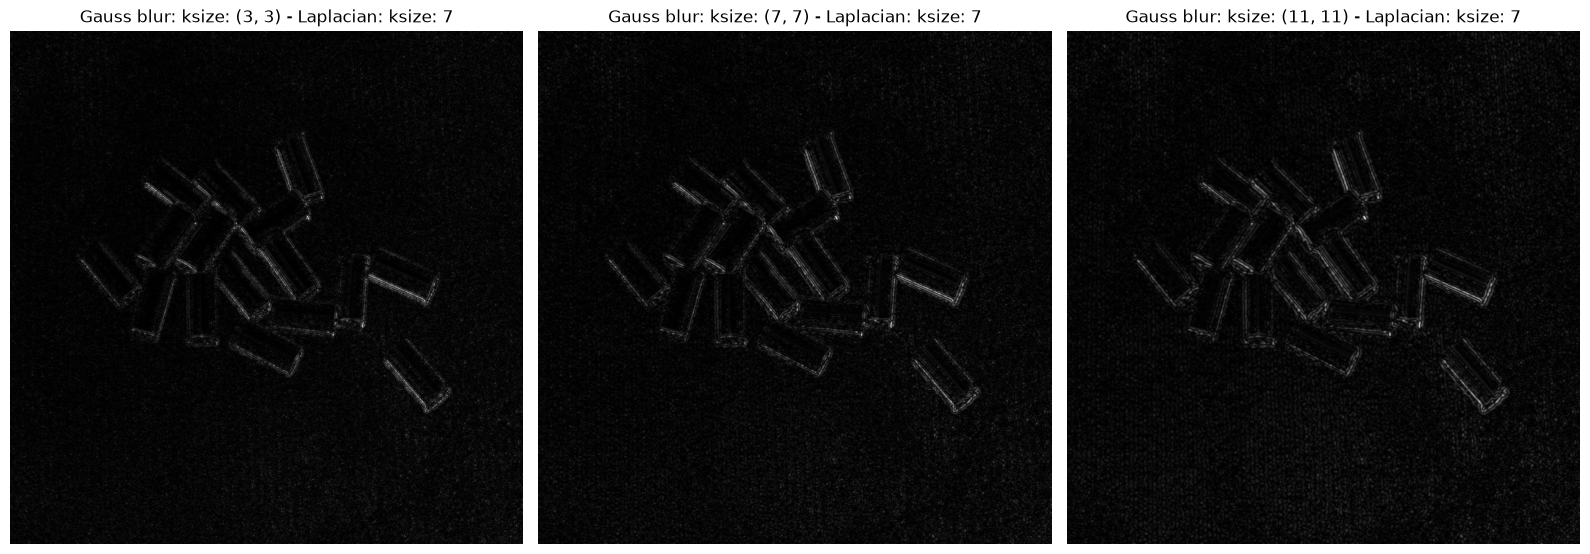

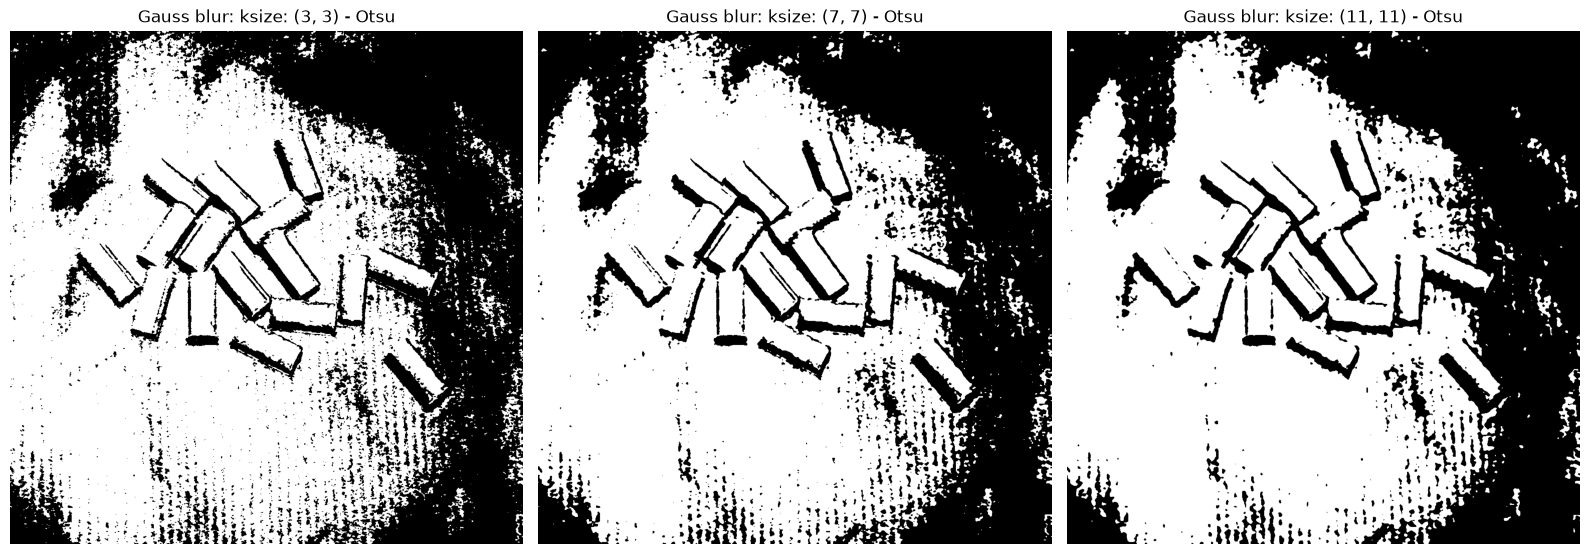

In [442]:
def sobel(images, k):
    out = []
    for (description, image) in images:
        gx = cv.Sobel(image, cv.CV_64F, 1, 0, ksize=k)
        gy = cv.Sobel(image, cv.CV_64F, 0, 1, ksize=k)
        sobel = cv.magnitude(gx, gy)
        out.append((f"{description} - Sobel: ksize: {k}", sobel))

    return out

def laplacian(images, ksize):
    out = []
    for description, image in images:
        for kernel in ksize:
            lap = cv.Laplacian(image, cv.CV_64F, ksize=kernel)
            lap = np.abs(lap)
            lap_uint8 = cv.normalize(
                                    lap, None, 0, 255, cv.NORM_MINMAX
                                ).astype(np.uint8)
            out.append((f"{description} - Laplacian: ksize: {kernel}", lap_uint8))

    return out

def canny(images, thresholds):
    out = []
    for description, image in images:
        for low, high in thresholds:
            edges = cv.Canny(image, low, high)
            out.append((f"{description} - Canny ({low}, {high})", edges))

    return out

def otsu(images, inv=False):
    out = []
    for description, image in images:
            if inv:
                threshold, binary = cv.threshold(
                image,
                0,
                255,
                cv.THRESH_BINARY_INV + cv.THRESH_OTSU
                )
                out.append((f"{description} - Otsu", binary))

            else:
                threshold, binary = cv.threshold(
                image,
                0,
                255,
                cv.THRESH_BINARY + cv.THRESH_OTSU
                )
                out.append((f"{description} - Otsu", binary))

    return out

gaussblur_hsv_g = gaussian_blur(hsv_g, [(3,3), (7,7), (11,11)])
gaussblur_lab_g = gaussian_blur(lab_g, [(3,3), (7,7), (11,11)])

sobel_ = sobel(gaussblur_hsv_g,7)
display_images(sobel_, zoom=0)

canny_ = canny(gaussblur_hsv_g, [(50, 150)])
display_images(canny_, zoom=0)

lap_ = laplacian(gaussblur_hsv_g, [7])
display_images(lap_)

otsu_ = otsu(gaussblur_hsv_g, inv=True)
display_images(otsu_, zoom=0)

canny = cv.Canny(hsv_g, 50, 150)

Otsu with colorspace hsv and colorchannel g shows promesing results. Especially because the area inside the tubes are for the most part completly white, with a distinct edge, further I want to try to make the background less birght.

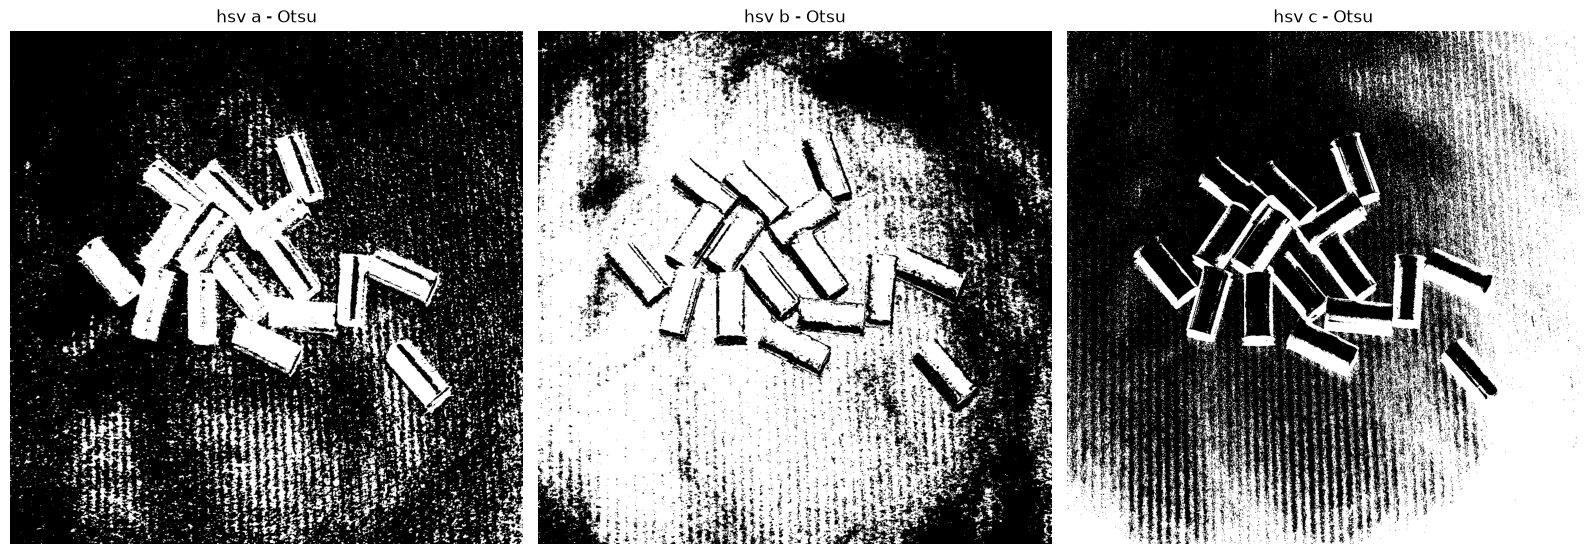

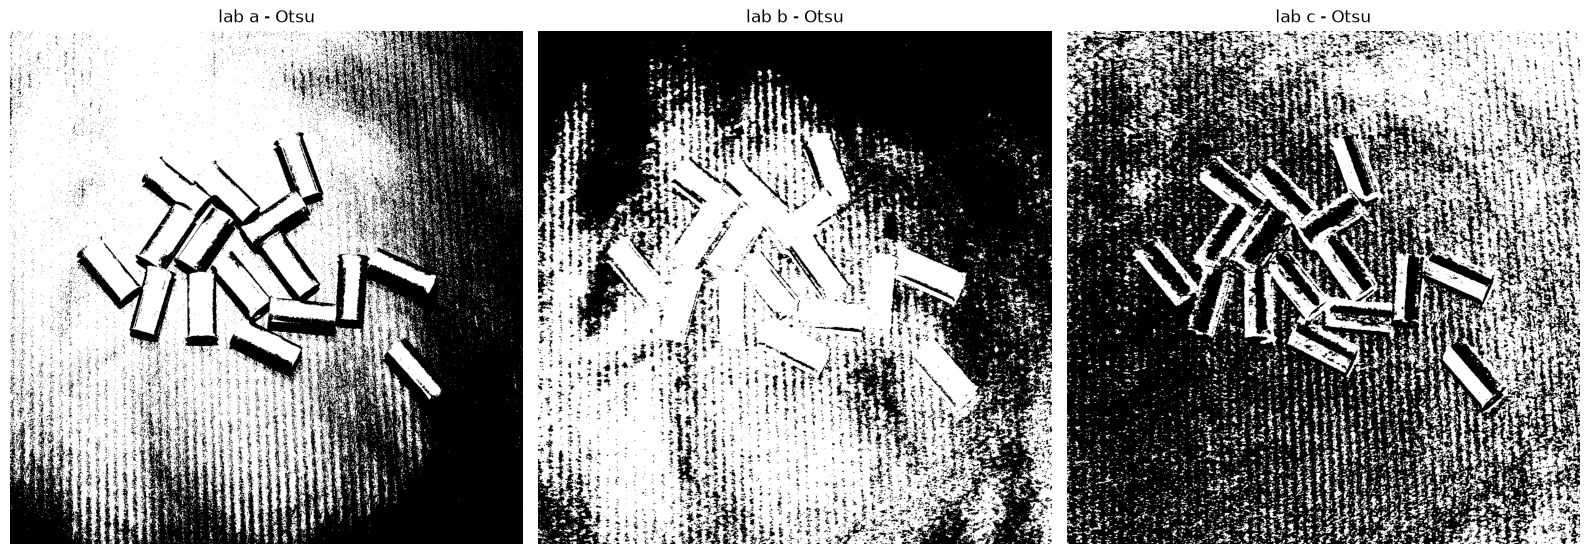

In [443]:
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
lab = cv.cvtColor(img, cv.COLOR_BGR2Lab)

ha, hb, hc = cv.split(hsv)
la, lb, lc = cv.split(lab)

hsv_mask = [
    ("hsv a", ha),
    ("hsv b", hb),
    ("hsv c", hc)
]
otsu_hsv = otsu(hsv_mask, inv=True)
display_images(otsu_hsv)

lab_mask = [
    ("lab a", la),
    ("lab b", lb),
    ("lab c", lc)
]
otsu_lab = otsu(lab_mask)
display_images(otsu_lab)


hsv a, hsv b and lab b looks promesing, since hsv has a weaker background, hsv b has full tubes and lab b looks like hsv b but less background. I will try to combine these with a masking

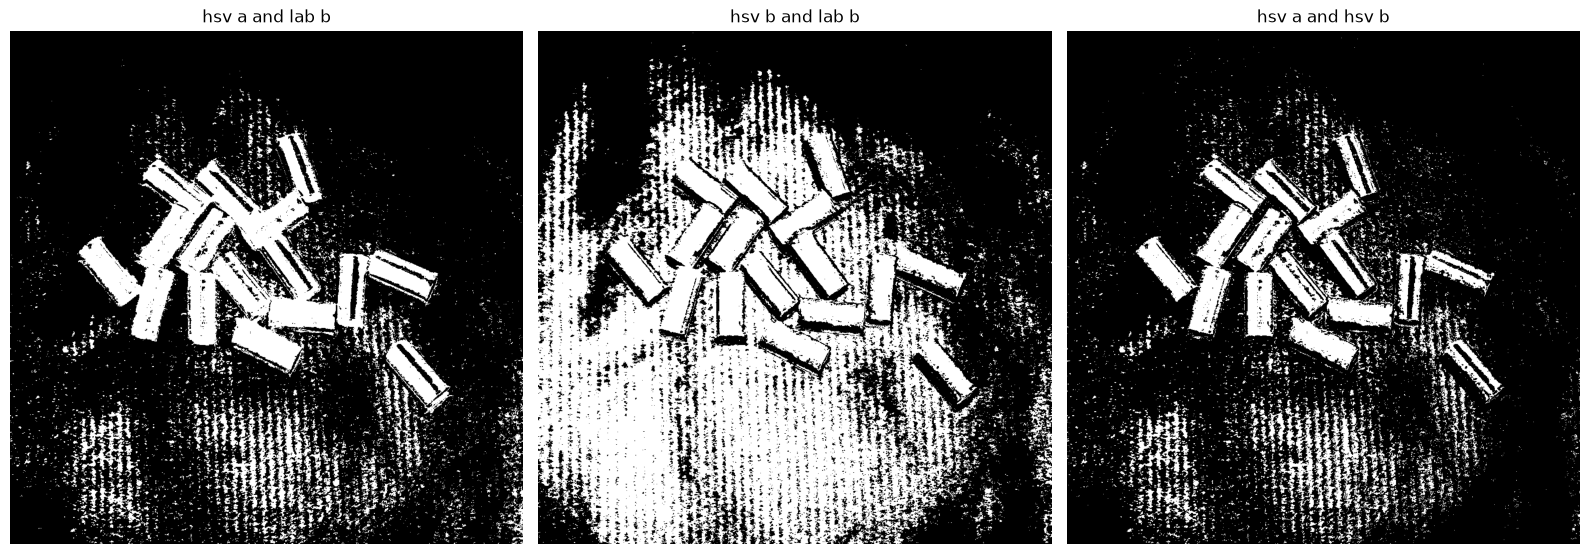

In [444]:
hsv_a = otsu_hsv[0][1]
hsv_b = otsu_hsv[1][1]
lab_b = otsu_lab[1][1]

combined1 = hsv_a & lab_b
combined2 = hsv_b & lab_b
combined3 = hsv_a & hsv_b

combined = [
    ("hsv a and lab b", combined1),
    ("hsv b and lab b", combined2),
    ("hsv a and hsv b", combined3)
]

display_images(combined)

A combination of hsv a and lab a is the best combination, where it keeps the filled tubes, and reduces noise form the background

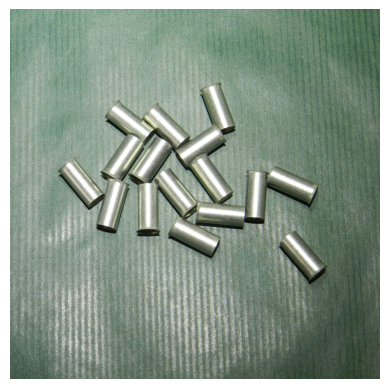

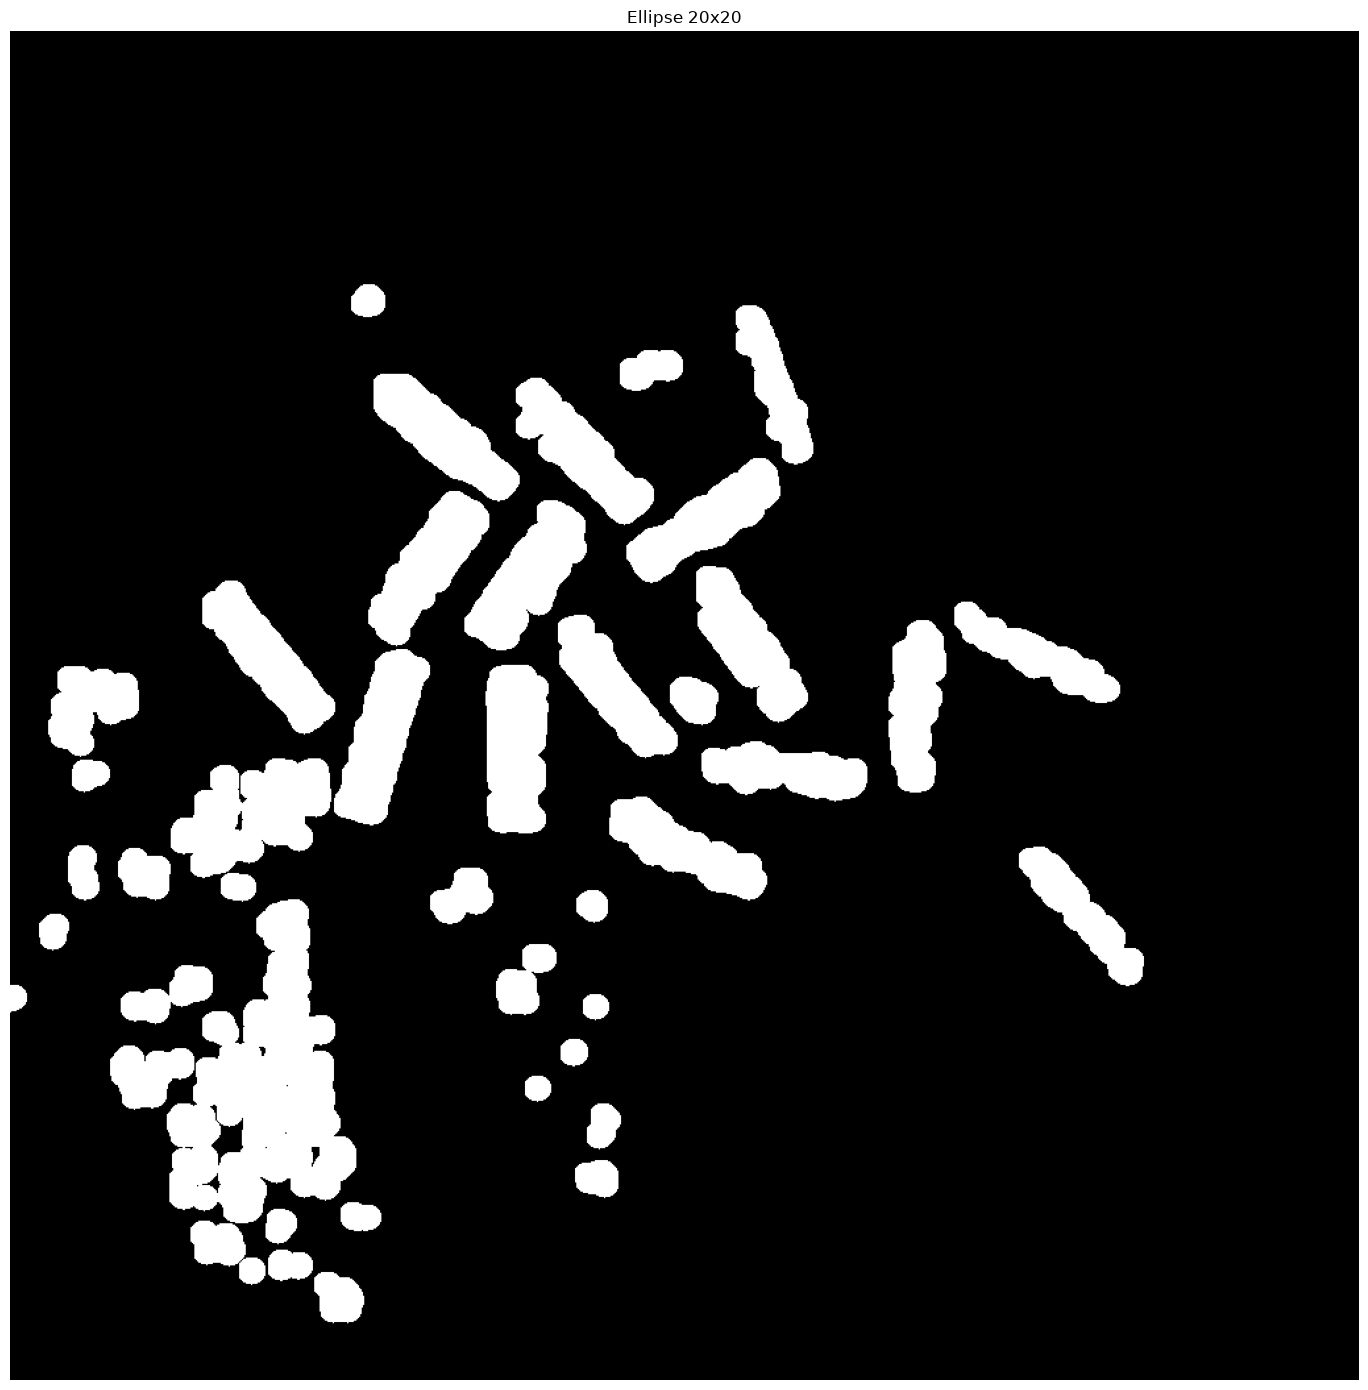

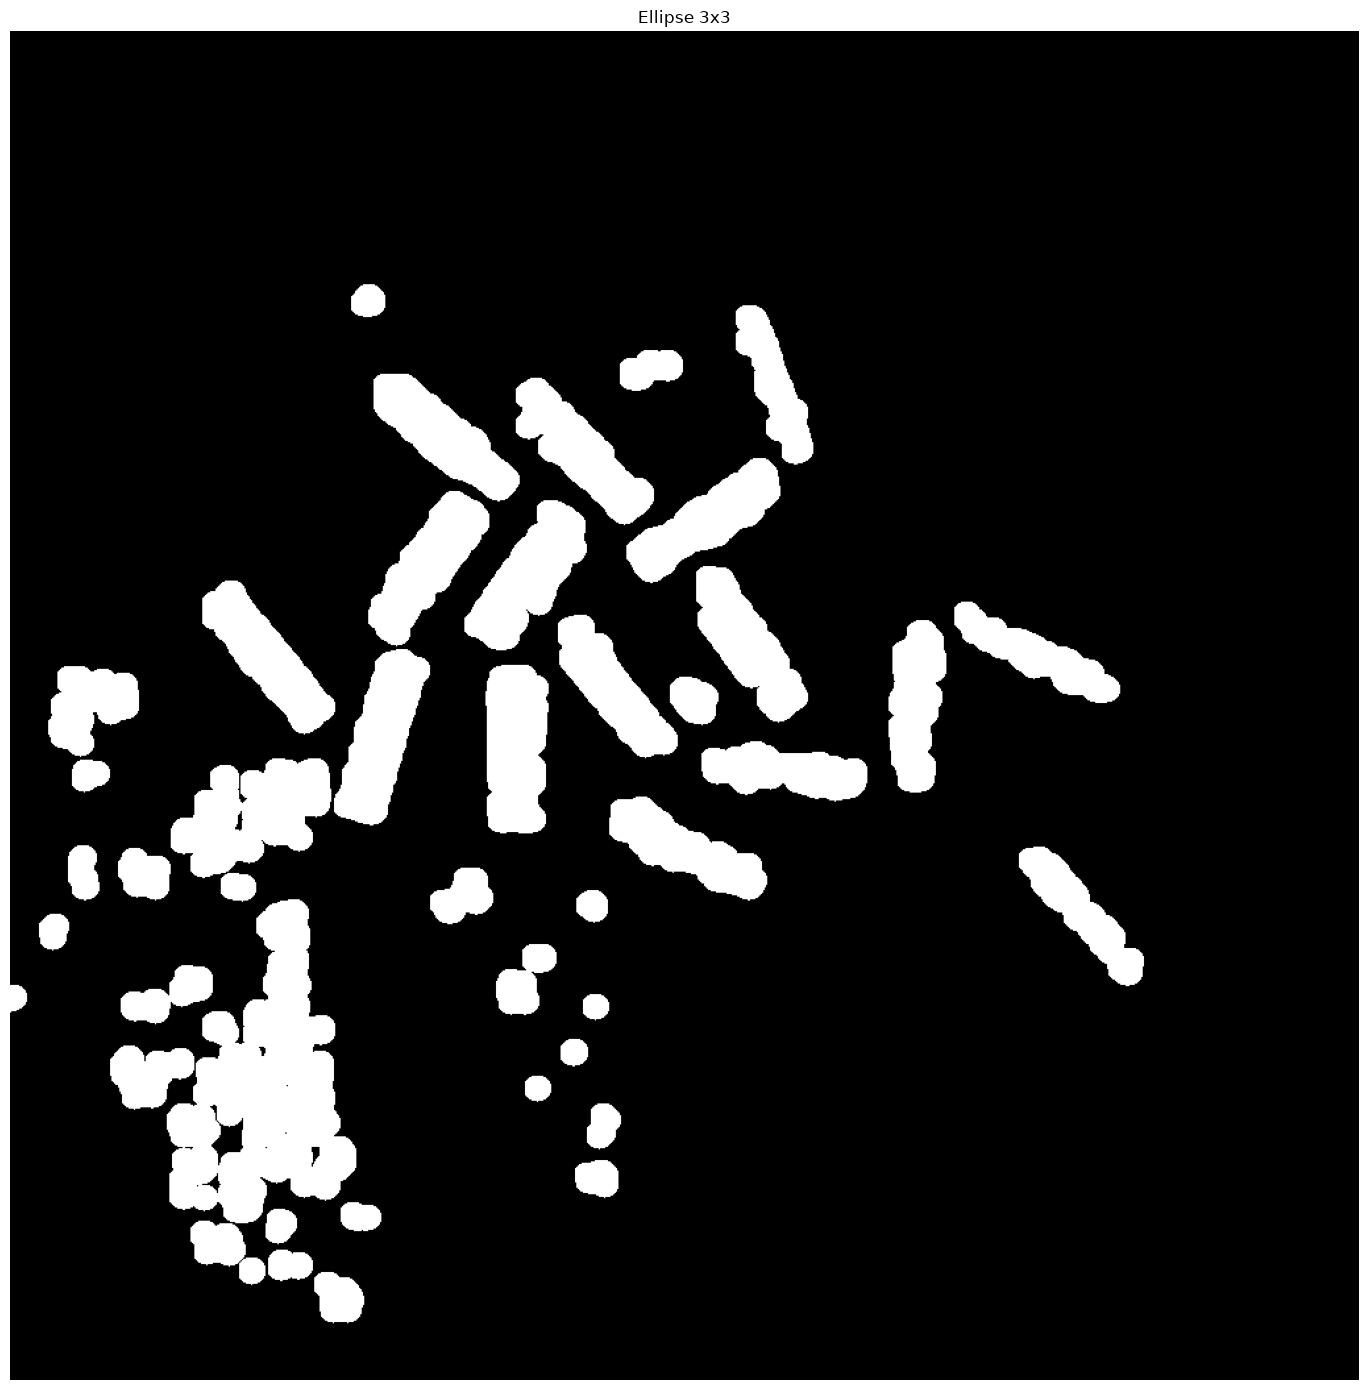

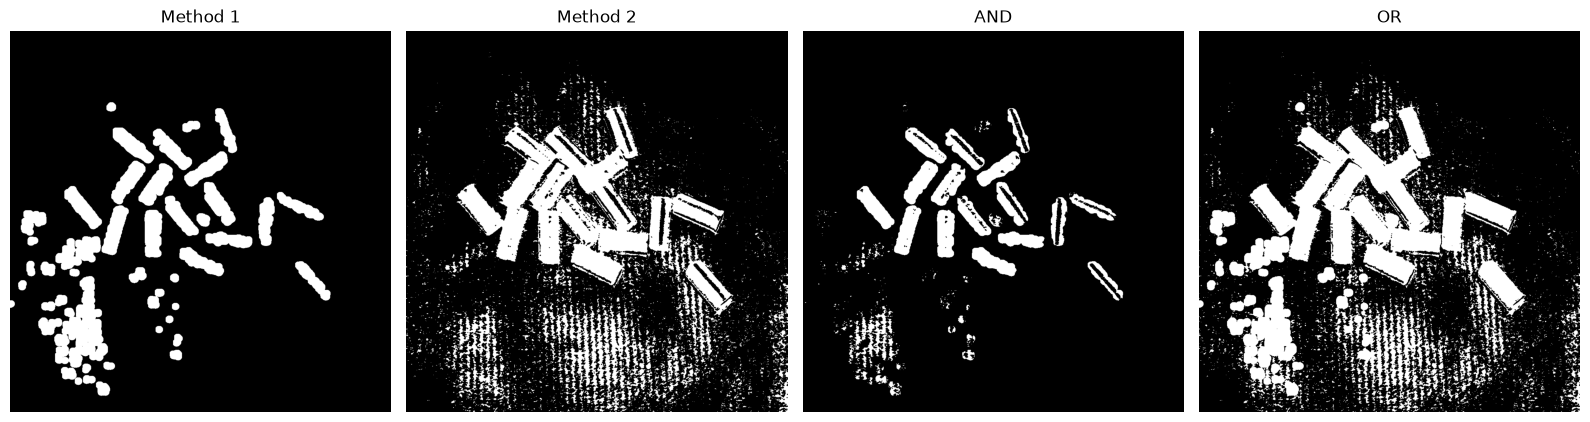

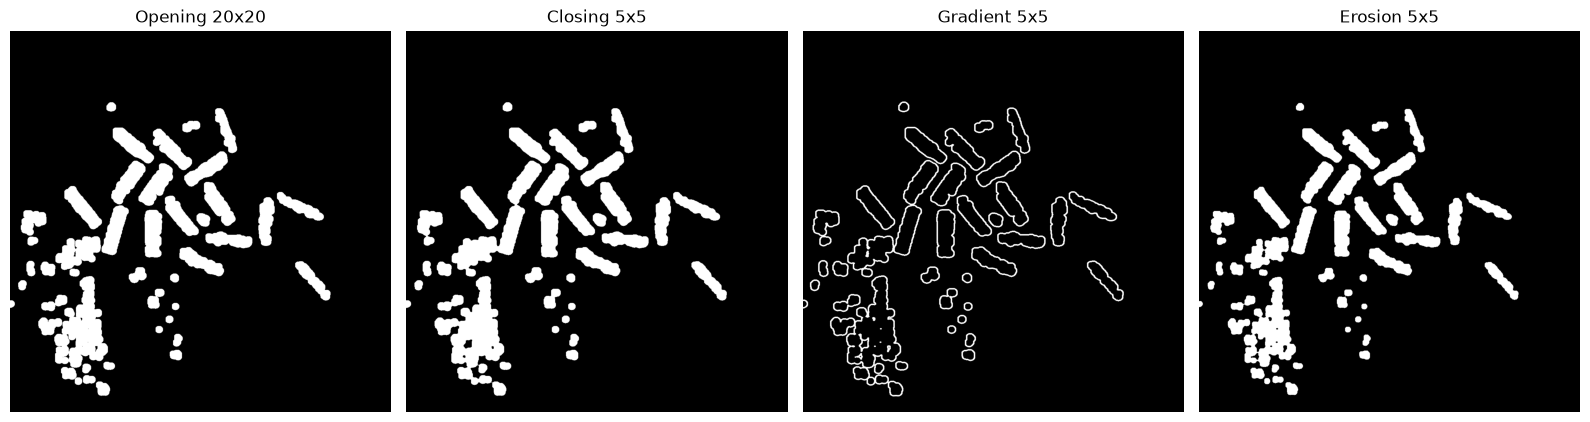

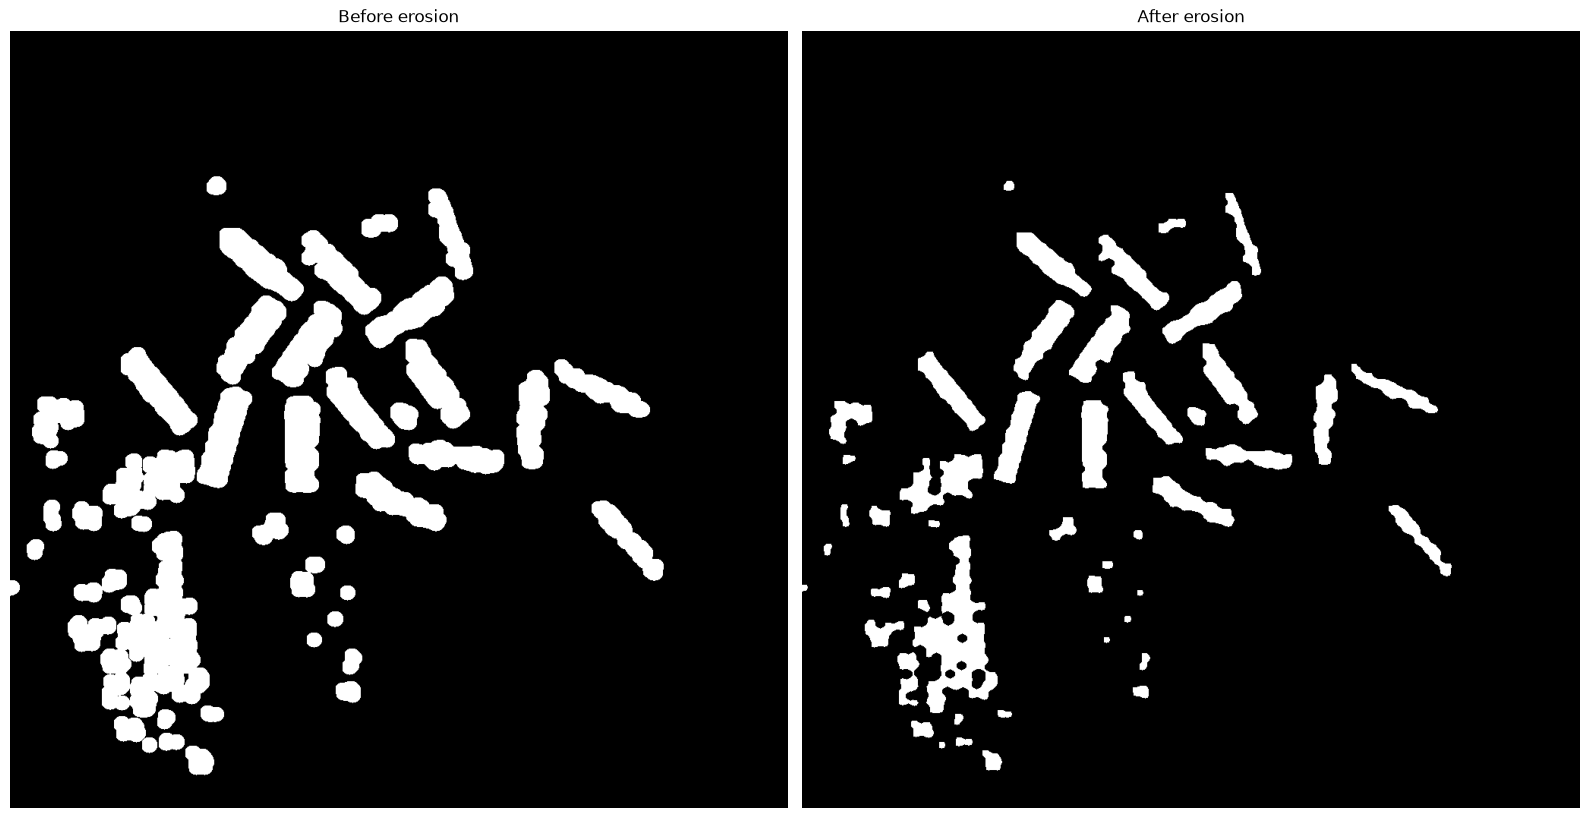

In [451]:

img_org = cv.cvtColor(img, cv.COLOR_BGR2RGB) # original image

plt.imshow(img_org)
plt.axis("off")
plt.show()

binary1 = combined2
results = []

for k in [20]:
    kernel = cv.getStructuringElement(
        cv.MORPH_ELLIPSE, (k, k)
    )
    
    opened = cv.morphologyEx(
        binary1,
        cv.MORPH_OPEN,
        kernel
    )

    results.append((f"Ellipse {k}x{k}", opened))

display_images(results)

binary2 = combined1
results = []

for k in [3]:
    kernel = cv.getStructuringElement(
        cv.MORPH_ELLIPSE, (k, k)
    )
    
    opened1 = cv.morphologyEx(
        binary2,
        cv.MORPH_CLOSE,
        kernel
    )

    results.append((f"Ellipse {k}x{k}", opened))

display_images(results)

# Bruk de faktiske variablene fra de to metodene dine
# mask1 = resultat fra første metode
# mask2 = resultat fra andre metode

combined_and = opened & opened1
combined_or = opened | opened1

display_images([
    ("Method 1", opened),
    ("Method 2", opened1),
    ("AND", combined_and),
    ("OR", combined_or)
])

kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (5, 5))

closing = cv.morphologyEx(opened, cv.MORPH_CLOSE, kernel)
gradient = cv.morphologyEx(opened, cv.MORPH_GRADIENT, kernel)
eroded = cv.erode(opened, kernel)

display_images([
    ("Opening 20x20", opened),
    ("Closing 5x5", closing),
    ("Gradient 5x5", gradient),
    ("Erosion 5x5", eroded)
])

kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (7,7))

eroded = cv.erode(opened, kernel, iterations=2)

display_images([
    ("Before erosion", opened),
    ("After erosion", eroded)
])

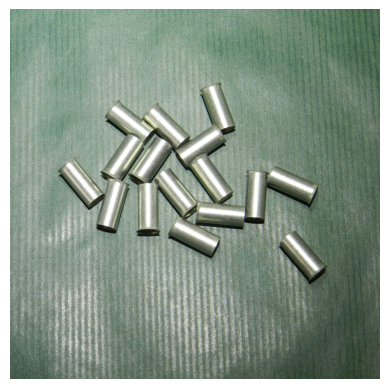

Antall før: 45
Antall etter: 30


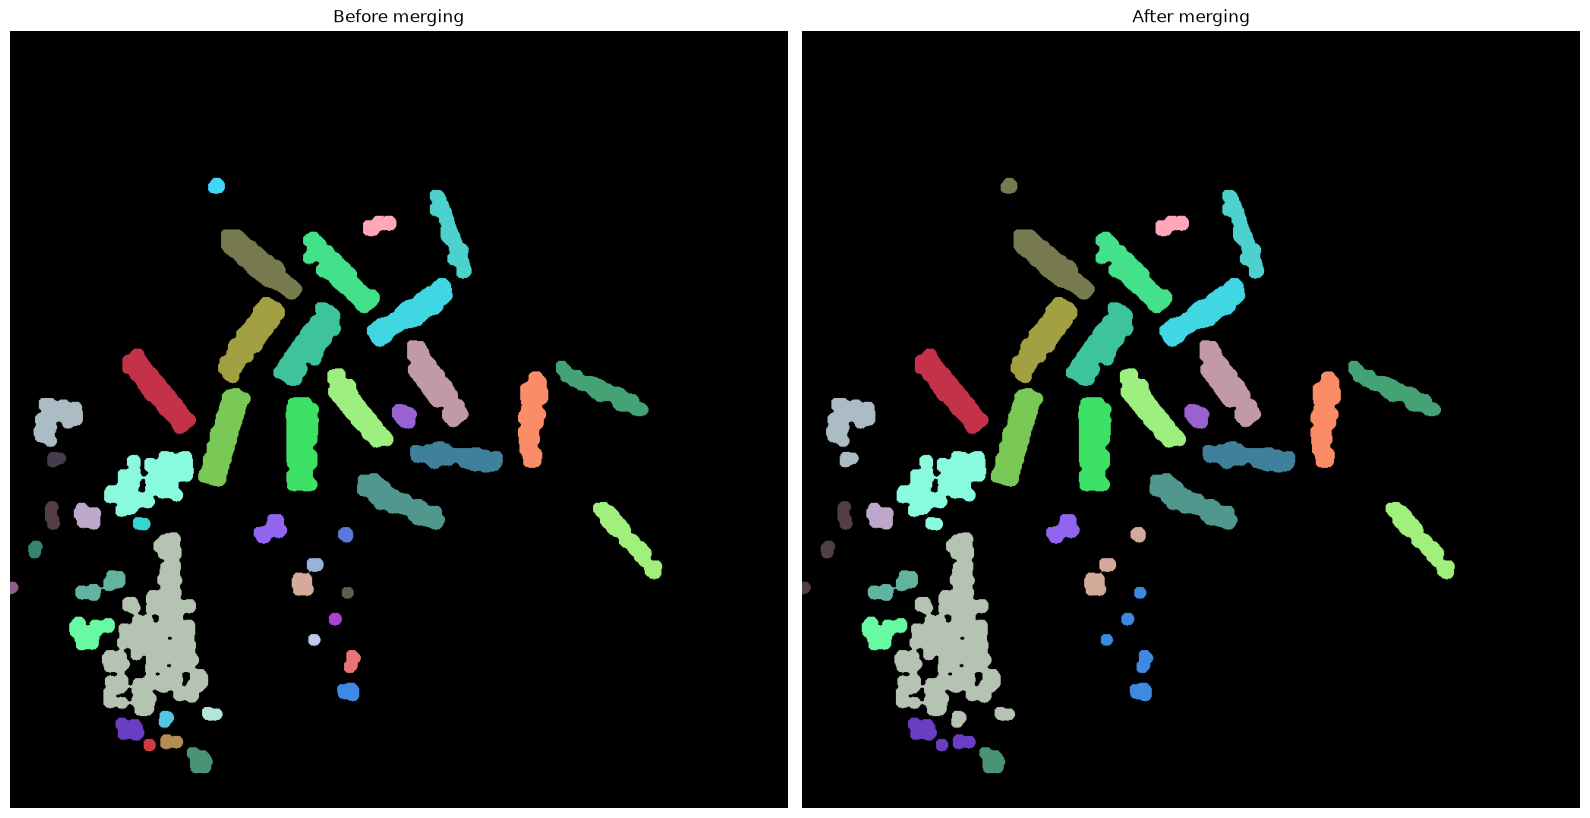

In [446]:
from scipy.ndimage import distance_transform_edt

num_labels, labels, stats, centroids = cv.connectedComponentsWithStats(
    eroded, connectivity=8
)

# Deretter while-løkken din ...

img_org = cv.cvtColor(img, cv.COLOR_BGR2RGB) # original image

plt.imshow(img_org)
plt.axis("off")
plt.show()

merged = labels.copy()
min_area = 800

while True:
    ids, counts = np.unique(merged[merged > 0], return_counts=True)

    if len(ids) < 2:
        break

    # Finn minste komponent
    smallest_idx = np.argmin(counts)
    small_id = ids[smallest_idx]

    # Stopp når alle er store nok
    if counts[smallest_idx] >= min_area:
        break

    # Finn nærmeste komponent, uansett størrelse
    small_mask = merged == small_id
    distances = distance_transform_edt(~small_mask)

    nearest_id = min(
        ids[ids != small_id],
        key=lambda i: distances[merged == i].min()
    )

    # Slå sammen
    merged[small_mask] = nearest_id

print("Antall før:", num_labels - 1)
print("Antall etter:", len(np.unique(merged)) - 1)

colored_before = np.zeros((*labels.shape, 3), dtype=np.uint8)
colored_after = np.zeros((*merged.shape, 3), dtype=np.uint8)

rng = np.random.default_rng(42)

# Samme farge for samme komponent-ID
colors = rng.integers(50, 256, size=(num_labels, 3), dtype=np.uint8)

for i in range(1, num_labels):
    colored_before[labels == i] = colors[i]
    colored_after[merged == i] = colors[i]

display_images([
    ("Before merging", colored_before),
    ("After merging", colored_after)
])